D:\deep-learning-labs\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
610/610 - 7s - 11ms/step - accuracy: 0.0880 - loss: 7.1744
Epoch 2/20
610/610 - 9s - 14ms/step - accuracy: 0.0918 - loss: 6.6096
Epoch 3/20
610/610 - 5s - 8ms/step - accuracy: 0.1055 - loss: 6.3360
Epoch 4/20
610/610 - 4s - 7ms/step - accuracy: 0.1187 - loss: 6.0823
Epoch 5/20
610/610 - 4s - 7ms/step - accuracy: 0.1241 - loss: 5.8386
Epoch 6/20
610/610 - 5s - 7ms/step - accuracy: 0.1282 - loss: 5.6366
Epoch 7/20
610/610 - 5s - 8ms/step - accuracy: 0.1324 - loss: 5.4671
Epoch 8/20
610/610 - 5s - 9ms/step - accuracy: 0.1363 - loss: 5.3160
Epoch 9/20
610/610 - 5s - 7ms/step - accuracy: 0.1384 - loss: 5.2720
Epoch 10/20
610/610 - 6s - 11ms/step - accuracy: 0.1452 - loss: 5.1115
Epoch 11/20
610/610 - 5s - 8ms/step - accuracy: 0.1507 - loss: 4.9435
Epoch 12/20
610/610 - 5s - 8ms/step - accuracy: 0.1557 - loss: 4.8747
Epoch 13/20
610/610 - 5s - 8ms/step - accuracy: 0.1580 - loss: 4.7187
Epoch 14/20
610/610 - 5s - 8ms/step - accuracy: 0.1647 - loss: 4.5527
Epoch 15/20
610/610 - 5s -

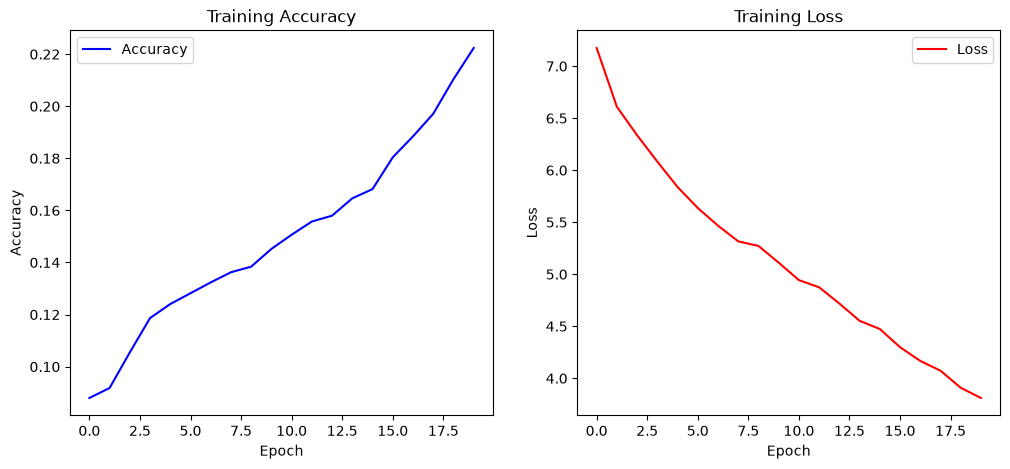

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

# Read the CSV file
df = pd.read_csv("poi.csv", encoding="latin1", sep=';')# <-- replace with your actual file path
df.head(10)
corpus = df["Label"].dropna().astype(str).tolist()  # get all values from the 'Name' column

# Step 1: Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)
total_words = len(tokenizer.word_index) + 1

# Convert text into sequences of tokens
input_sequences = []
for line in corpus:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

# Pad sequences and split into inputs (X) and outputs (y)
max_seq_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = np.array(y)

# Step 2: Build the LSTM model
model = Sequential([
    Embedding(total_words, 10, input_length=max_seq_len - 1),
    LSTM(150),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Convert output labels (y) to categorical format
y = to_categorical(y, num_classes=total_words)

# Train the model
history = model.fit(X, y, epochs=20, verbose=2)

# ========= Plot accuracy and loss =========
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Accuracy', color='blue')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Loss', color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()

plt.show()



In [2]:

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len-1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        
        # Convert index back to word
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                seed_text += " " + word
                break
    return seed_text


print("\nGenerated text:")
print(generate_text("zoologico santa", next_words=1))



Generated text:
zoologico santa maria


- Train during 500 epochs and graph the results and observe how metric improves.
- Try different senteces lenghts (1, 3, 5) and report
- - Try different sizes of lstm modules #   LSTM(150), 100, 200

In [3]:
import sys
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
from tensorflow.keras.utils import set_random_seed

# Permite importar src al iniciar Jupyter desde la carpeta del notebook.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Ejecuta el notebook dentro del proyecto deep-learning-labs.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import PROJECT_PATH
from src.utils import logger as log

logger = log.LOGGER
config = log.CONFIG
figure_directory = Path(config.paths.reports.figures)
if not figure_directory.exists():
    logger.warning("La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.")
    figure_directory = PROJECT_PATH / figure_directory
figure_directory.mkdir(parents=True, exist_ok=True)

2026-11-25 09:33:01 [WARNING] La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.


### Comparación de contextos y tamaños LSTM

Se entrenan las nueve combinaciones de 1, 3 y 5 palabras previas y 100, 150 y 200 unidades durante 500 épocas cada una. Todas utilizan los mismos ejemplos y una semilla común; los contextos se rellenan o truncan por la izquierda. La tabla y las gráficas muestran métricas de entrenamiento: no evalúan la generalización. La ejecución completa puede tardar mucho tiempo.

In [4]:
from IPython.display import display


def comparar_lstm(longitudes=(1, 3, 5), unidades=(100, 150, 200), epochs=500, verbose=0):
    """Compara modelos LSTM para predecir la siguiente palabra del corpus.

    Cada longitud limita el número de palabras previas; los contextos se
    rellenan o truncan por la izquierda. Todas las configuraciones usan los
    mismos ejemplos y una semilla común. Las métricas son de entrenamiento.

    Args:
        longitudes: Cantidades máximas de palabras previas, sin duplicados.
        unidades: Tamaños de la capa LSTM que se van a comparar, sin duplicados.
        epochs: Número de épocas de entrenamiento por configuración.
        verbose: Nivel de salida de Keras durante el entrenamiento.

    Returns:
        Lista de diccionarios con longitud, unidades, modelo e historial.
        Además, muestra una tabla y guarda y muestra las curvas de métricas.

    Raises:
        ValueError: Si los parámetros son inválidos o no hay ejemplos.
    """
    # Validar las configuraciones antes de iniciar los entrenamientos.
    longitudes, unidades = tuple(longitudes), tuple(unidades)
    for nombre, valores in (("longitudes", longitudes), ("unidades", unidades),
                            ("epochs", (epochs,))):
        if not valores or any(not isinstance(valor, int) or isinstance(valor, bool)
                              or valor < 1 for valor in valores):
            logger.error("%s debe contener enteros positivos", nombre)
            raise ValueError(f"{nombre} debe contener enteros positivos")
    if len(set(longitudes)) != len(longitudes) or len(set(unidades)) != len(unidades):
        logger.error("Las longitudes y unidades no deben repetirse")
        raise ValueError("Las longitudes y unidades no deben repetirse")

    # Construir una sola colección de ejemplos para todas las configuraciones.
    contextos, objetivos = [], []
    for linea in corpus:
        tokens = tokenizer.texts_to_sequences([linea])[0]
        for i in range(1, len(tokens)):
            contextos.append(tokens[:i])
            objetivos.append(tokens[i])
    if not contextos:
        logger.error("El corpus no contiene secuencias de al menos dos palabras")
        raise ValueError("El corpus debe contener al menos una secuencia de dos palabras")
    etiquetas = np.asarray(objetivos, dtype=np.int32)
    logger.info("Comparación iniciada: %d ejemplos y %d configuraciones de %d épocas",
                len(contextos), len(longitudes) * len(unidades), epochs)
    logger.warning("Las métricas de entrenamiento no miden la generalización")

    # Entrenar cada combinación y registrar la evolución de sus métricas.
    resultados, resumen = [], []
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for longitud in longitudes:
        entradas = pad_sequences(contextos, maxlen=longitud, padding="pre", truncating="pre")
        logger.debug("Contexto %d: dimensiones de entrada %s", longitud, entradas.shape)
        for n_unidades in unidades:
            etiqueta = f"Contexto={longitud}, LSTM={n_unidades}"
            logger.info("Entrenando %s", etiqueta)
            set_random_seed(config.project.get("seed", 42))
            modelo = Sequential([
                Embedding(total_words, 10),
                LSTM(n_unidades),
                Dense(total_words, activation="softmax"),
            ])
            modelo.compile(loss="sparse_categorical_crossentropy", optimizer="adam",
                           metrics=["accuracy"])
            try:
                historial = modelo.fit(entradas, etiquetas, epochs=epochs, verbose=verbose).history
            except Exception:
                logger.exception("Falló el entrenamiento de %s", etiqueta)
                plt.close(fig)
                raise
            accuracy, loss = historial["accuracy"], historial["loss"]
            axes[0].plot(range(1, len(accuracy) + 1), accuracy, label=etiqueta)
            axes[1].plot(range(1, len(loss) + 1), loss, label=etiqueta)
            resumen.append({"Contexto": longitud, "Unidades LSTM": n_unidades,
                            "Accuracy inicial": accuracy[0], "Accuracy final": accuracy[-1],
                            "Cambio accuracy (p.p.)": 100 * (accuracy[-1] - accuracy[0]),
                            "Loss inicial": loss[0], "Loss final": loss[-1],
                            "Cambio loss": loss[-1] - loss[0]})
            logger.info("%s: accuracy %.4f -> %.4f; loss %.4f -> %.4f",
                        etiqueta, accuracy[0], accuracy[-1], loss[0], loss[-1])
            resultados.append({"longitud": longitud, "unidades": n_unidades,
                               "modelo": modelo, "historial": historial})

    # Presentar el informe y guardar las curvas sin sobrescribir ejecuciones anteriores.
    display(pd.DataFrame(resumen).round(4))
    for axis, titulo in zip(axes, ("Accuracy de entrenamiento", "Loss de entrenamiento")):
        axis.set_title(titulo)
        axis.set_xlabel("Época")
        axis.set_ylabel(titulo)
        axis.legend(fontsize="small")
        axis.grid(True, alpha=0.3)
    fig.tight_layout()
    ruta_figura = figure_directory / f"comparacion_lstm_{uuid4().hex}.png"
    try:
        fig.savefig(ruta_figura, dpi=150, bbox_inches="tight")
    except OSError:
        logger.exception("No se pudo guardar la gráfica en %s", ruta_figura)
        plt.close(fig)
        raise
    logger.info("Gráfica guardada en %s", ruta_figura)
    plt.show()
    return resultados

2026-11-25 09:33:01 [INFO] Comparación iniciada: 19508 ejemplos y 9 configuraciones de 500 épocas
2026-11-25 09:33:01 [WARNING] Las métricas de entrenamiento no miden la generalización
2026-11-25 09:33:01 [DEBUG] Contexto 1: dimensiones de entrada (19508, 1)
2026-11-25 09:33:01 [INFO] Entrenando Contexto=1, LSTM=100
2026-11-25 09:54:15 [INFO] Contexto=1, LSTM=100: accuracy 0.0893 -> 0.2879; loss 7.3983 -> 3.0837
2026-11-25 09:54:15 [INFO] Entrenando Contexto=1, LSTM=150
2026-11-25 10:22:56 [INFO] Contexto=1, LSTM=150: accuracy 0.0893 -> 0.2877; loss 7.3472 -> 3.0606
2026-11-25 10:22:56 [INFO] Entrenando Contexto=1, LSTM=200
2026-11-25 11:13:46 [INFO] Contexto=1, LSTM=200: accuracy 0.0897 -> 0.2895; loss 7.3204 -> 3.0411
2026-11-25 11:13:46 [DEBUG] Contexto 3: dimensiones de entrada (19508, 3)
2026-11-25 11:13:46 [INFO] Entrenando Contexto=3, LSTM=100
2026-11-25 11:49:36 [INFO] Contexto=3, LSTM=100: accuracy 0.0890 -> 0.5360; loss 7.2846 -> 1.6596
2026-11-25 11:49:36 [INFO] Entrenando C

,Contexto,Unidades LSTM,Accuracy inicial,Accuracy final,Cambio accuracy (p.p.),Loss inicial,Loss final,Cambio loss
0,1,100,0.0893,0.2879,19.8636,7.3983,3.0837,-4.3145
1,1,150,0.0893,0.2877,19.8329,7.3472,3.0606,-4.2866
2,1,200,0.0897,0.2895,19.9815,7.3204,3.0411,-4.2793
3,3,100,0.0890,0.5360,44.6996,7.2846,1.6596,-5.6251
4,3,150,0.0892,0.6303,54.1111,7.2735,1.0699,-6.2036
5,3,200,0.0895,0.6184,52.8860,7.2712,1.1200,-6.1512
6,5,100,0.0890,0.6432,55.4234,7.2285,1.1201,-6.1084
7,5,150,0.0891,0.6813,59.2167,7.2173,0.9402,-6.2771
8,5,200,0.0895,0.6434,55.3978,7.2239,1.1243,-6.0996


2026-11-25 15:46:49 [INFO] Gráfica guardada en D:\deep-learning-labs\reports\figures\comparacion_lstm_351658fc82a8464a882177b9cebb672f.png


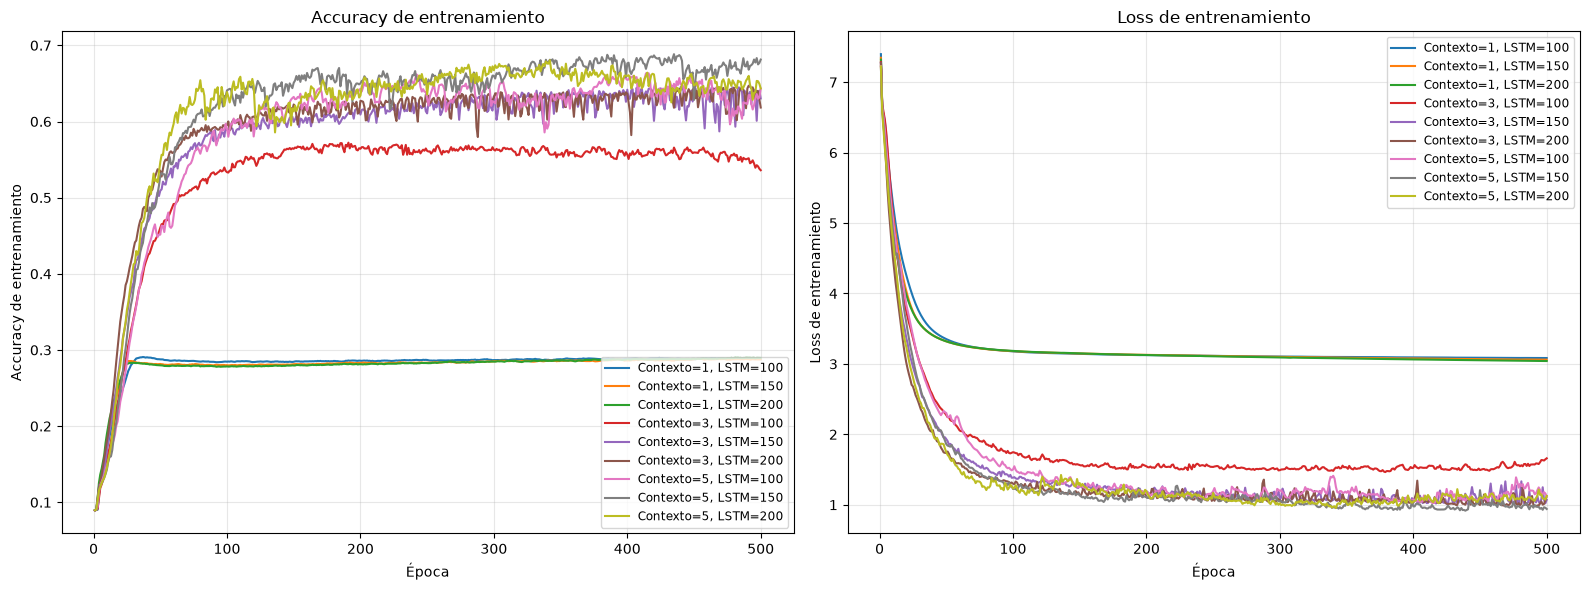

In [5]:
resultados_comparacion = comparar_lstm()